# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ellen Tri Alfiana Salua
- **Email:** elensalua@gmail.com
- **ID Dicoding:** ellen_tri_alfiana_salua_N0og

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana tren total penyewaan sepeda (`cnt`) per bulan dan per musim pada tahun 2011 dibandingkan dengan tahun 2012, dan kondisi cuaca (`weathersit`) mana yang paling menurunkan rata-rata penyewaan harian selama periode 2011 hingga 2012?
  - **Specific:** objek analisis adalah `cnt`, dengan dimensi bulan, musim, tahun, dan kondisi cuaca.
  - **Measurable:** diukur dengan agregasi jumlah (`sum`) dan rata-rata (`mean`) kolom `cnt`, serta persentase selisih terhadap kondisi cuaca Cerah.
  - **Action-Oriented:** menentukan waktu penambahan armada dan strategi saat cuaca kurang baik.
  - **Relevant:** tren musiman dan cuaca merupakan faktor eksternal utama yang memengaruhi permintaan.
  - **Time-bound:** periode dataset, yaitu 2011 hingga 2012.
- **Pertanyaan 2:** Pada jam berapa permintaan penyewaan mencapai puncak pada hari kerja dibandingkan dengan hari libur selama 2011 hingga 2012, dan bagaimana perbandingan kontribusi pengguna `registered` terhadap pengguna `casual` pada jam-jam tersebut?
  - **Specific:** objek analisis adalah `cnt` per jam (`hr`), dengan dimensi jenis hari dan tipe pengguna.
  - **Measurable:** diukur dengan rata-rata `cnt` per jam dan jumlah penyewaan per tipe pengguna (satuan: penyewaan per jam).
  - **Action-Oriented:** menentukan jadwal redistribusi armada per jam.
  - **Relevant:** pola per jam menjadi dasar operasional harian.
  - **Time-bound:** periode dataset, yaitu 2011 hingga 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print('Versi pandas  :', pd.__version__)
print('Versi numpy   :', np.__version__)
print('Versi seaborn :', sns.__version__)

Versi pandas  : 3.1.1
Versi numpy   : 2.4.6
Versi seaborn : 0.13.2


## Data Wrangling

### Gathering Data

#### Memuat Data Harian dan Data per Jam

In [2]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('Data harian (day_df), bentuk data :', day_df.shape)
display(day_df.head())
print('\nData per jam (hour_df), bentuk data :', hour_df.shape)
display(hour_df.head())

Data harian (day_df), bentuk data : (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Data per jam (hour_df), bentuk data : (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Data harian (`day_df`) berisi 731 baris untuk dua tahun, sedangkan data per jam (`hour_df`) berisi 17.379 baris dengan tambahan kolom `hr`.
- Apabila lengkap, jumlah jam adalah 731 hari dikalikan 24 jam, yaitu 17.544 jam. Dengan demikian, terdapat 165 jam yang tidak tercatat (tidak ada transaksi atau sistem tidak beroperasi).
- Kolom `cnt` merupakan jumlah dari kolom `casual` dan `registered` (contoh pada baris pertama: 16 berasal dari 3 dan 13).
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` masih ternormalisasi pada rentang 0 hingga 1, kolom `dteday` masih bertipe string, dan kolom `season`, `weathersit`, `weekday`, serta `yr` masih berupa kode angka sehingga perlu dibersihkan.

### Assessing Data

#### Memeriksa Tipe Data dan Struktur Tabel

In [3]:
print('===== Info day_df =====')
day_df.info()
print('\n===== Info hour_df =====')
hour_df.info()

===== Info day_df =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

===== Info hour_df =====
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to

#### Memeriksa Nilai Kosong, Duplikasi, dan Ringkasan Statistik

In [4]:
for nama, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'===== {nama} =====')
    print('Jumlah nilai kosong per kolom:')
    print(df.isnull().sum())
    print('Jumlah baris duplikat   :', df.duplicated().sum())
    print('Jumlah instant duplikat :', df['instant'].duplicated().sum(), '\n')

display(day_df.describe())
display(hour_df.describe())

===== day_df =====
Jumlah nilai kosong per kolom:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Jumlah baris duplikat   : 0
Jumlah instant duplikat : 0 

===== hour_df =====
Jumlah nilai kosong per kolom:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Jumlah baris duplikat   : 0
Jumlah instant duplikat : 0 



,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


#### Memeriksa Nilai Unik Kolom Kategorikal

In [5]:
for kol in ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']:
    print(f'{kol:12s} : {sorted(int(v) for v in day_df[kol].unique())}')

season       : [1, 2, 3, 4]
yr           : [0, 1]
mnth         : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday      : [0, 1]
weekday      : [0, 1, 2, 3, 4, 5, 6]
workingday   : [0, 1]
weathersit   : [1, 2, 3]


#### Memeriksa Outlier dengan Metode IQR

In [6]:
def cek_outlier(df, kolom):
    q1, q3 = df[kolom].quantile(0.25), df[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    jumlah = int(((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum())
    return pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                      'Batas Bawah': batas_bawah, 'Batas Atas': batas_atas,
                      'Jumlah Outlier': jumlah,
                      'Persentase (%)': round(jumlah / len(df) * 100, 2)})


kolom_numerik = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
display(pd.DataFrame({k: cek_outlier(day_df, k) for k in kolom_numerik}).T)

,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
temp,0.337083,0.655417,0.318333,-0.140416,1.132916,0.0,0.00
atemp,0.337842,0.608602,0.270760,-0.068297,1.014741,0.0,0.00
hum,0.520000,0.730209,0.210209,0.204687,1.045521,2.0,0.27
windspeed,0.134950,0.233214,0.098265,-0.012447,0.380611,13.0,1.78
casual,315.500000,1096.000000,780.500000,-855.250000,2266.750000,44.0,6.02
registered,2497.000000,4776.500000,2279.500000,-922.250000,8195.750000,0.0,0.00
cnt,3152.000000,5956.000000,2804.000000,-1054.000000,10162.000000,0.0,0.00


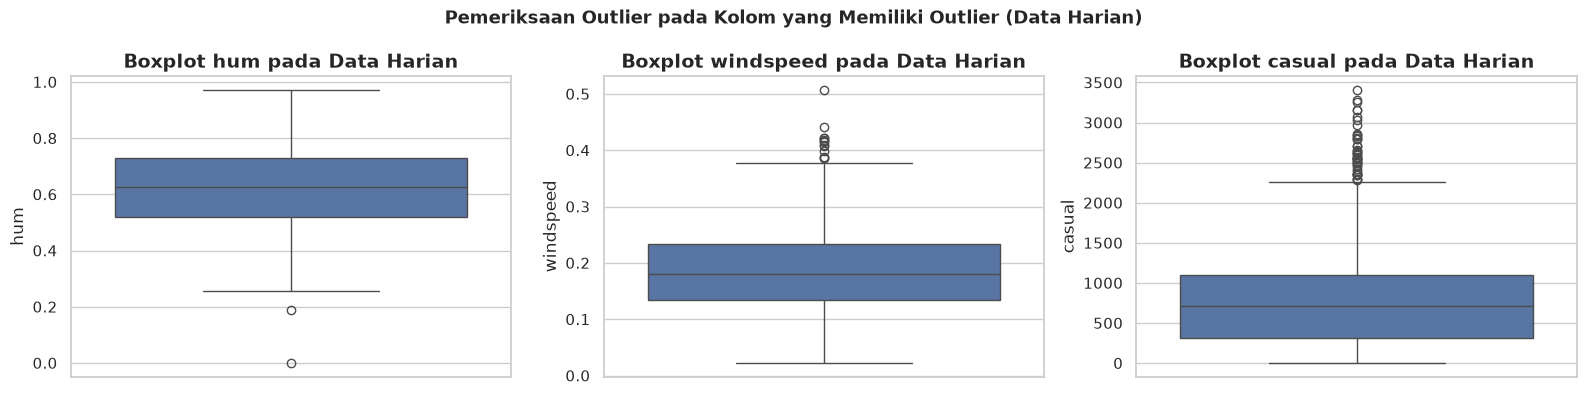

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kol in zip(axes, ['hum', 'windspeed', 'casual']):
    sns.boxplot(data=day_df, y=kol, ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot {kol} pada Data Harian')
plt.suptitle('Pemeriksaan Outlier pada Kolom yang Memiliki Outlier (Data Harian)',
             fontweight='bold')
plt.tight_layout()
plt.show()

#### Memeriksa Konsistensi Data Harian dan Data per Jam

In [8]:
harian_dari_jam = hour_df.groupby('dteday', as_index=False)['cnt'].sum()
cek = harian_dari_jam.merge(day_df[['dteday', 'cnt']], on='dteday',
                            suffixes=('_jam', '_hari'))
jam_per_hari = hour_df.groupby('dteday')['hr'].count()

print('Jumlah hari dengan total cnt berbeda :', (cek['cnt_jam'] != cek['cnt_hari']).sum())
print('Total cnt pada day_df                :', day_df['cnt'].sum())
print('Total cnt pada hour_df               :', hour_df['cnt'].sum())
print('Jumlah hari dengan data kurang dari 24 jam :', (jam_per_hari < 24).sum())
print('Total jam yang hilang                :', 731 * 24 - hour_df.shape[0])

# Kondisi cuaca pada data per jam dapat berubah dalam satu hari,
# sedangkan data harian hanya memiliki satu kondisi cuaca per hari.
hari_cuaca_berubah = (hour_df.groupby('dteday')['weathersit'].nunique() > 1).sum()
print('Jumlah hari dengan kondisi cuaca berubah dalam sehari (data per jam) :',
      hari_cuaca_berubah)

Jumlah hari dengan total cnt berbeda : 0
Total cnt pada day_df                : 3292679
Total cnt pada hour_df               : 3292679
Jumlah hari dengan data kurang dari 24 jam : 76
Total jam yang hilang                : 165
Jumlah hari dengan kondisi cuaca berubah dalam sehari (data per jam) : 577


**Steps to Take:**
- Mengubah kolom `dteday` menjadi tipe datetime.
- Memetakan kolom `season`, `weathersit`, `weekday`, `yr`, dan `mnth` menjadi label yang berurutan.
- Mengembalikan kolom `temp`, `atemp`, `hum`, dan `windspeed` ke satuan asli: `temp` dikalikan 41 (derajat Celsius), `atemp` dikalikan 50 (derajat Celsius), `hum` dikalikan 100 (persen), dan `windspeed` dikalikan 67 (km/jam).
- Mempertahankan outlier karena permintaan puncak merupakan informasi bisnis yang valid, tetapi menandainya dengan kolom penanda pada kolom yang memiliki outlier, yaitu `hum_pct`, `wind_kmh`, dan `casual`.
- Menambahkan kolom `day_type` (Hari Kerja atau Hari Libur) berdasarkan kolom `workingday`.
- Menambahkan kolom `cuaca_harian` pada data per jam agar analisis cuaca memakai dasar yang sama dengan data harian.
- Tidak perlu menangani nilai kosong dan duplikasi karena tidak ditemukan.

**Insight:**
- Kolom `dteday` bertipe string, bukan datetime, sehingga sulit digunakan untuk analisis waktu.
- Kolom kategorikal masih berupa kode angka (`season` 1 hingga 4, `weathersit`, `weekday`, `yr`) sehingga rawan salah tafsir.
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` masih ternormalisasi sehingga tidak terbaca dalam satuan nyata.
- Outlier ditemukan pada `windspeed` (13 data, 1,78%), `casual` (44 data, 6,02%), dan `hum` (2 data, 0,27%). Kolom `temp`, `atemp`, `registered`, dan `cnt` tidak memiliki outlier pada data harian.
- Data per jam tidak lengkap 24 jam per hari: 76 hari memiliki kurang dari 24 jam dan total 165 jam tidak tercatat.
- Total `cnt` per hari pada data harian identik dengan data per jam (0 hari berbeda), sehingga kedua data aman dianalisis berdampingan. Tidak ada nilai kosong maupun duplikasi.
- Kondisi cuaca pada data per jam berubah dalam satu hari pada 577 dari 731 hari. Oleh karena itu, analisis cuaca pada notebook ini memakai kondisi cuaca harian.

### Cleaning Data

#### Memperbaiki Tipe Data, Label Kategori, Satuan, dan Penanda Outlier

In [9]:
season_map = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
yr_map = {0: 2011, 1: 2012}
weather_map = {1: 'Cerah', 2: 'Berkabut', 3: 'Hujan Ringan', 4: 'Hujan Lebat'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu',
               4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
             7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}

urutan_bulan = list(month_map.values())
urutan_musim = ['Semi', 'Panas', 'Gugur', 'Dingin']
urutan_cuaca = ['Cerah', 'Berkabut', 'Hujan Ringan', 'Hujan Lebat']
urutan_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']


def clean_bike(df):
    df = df.copy()
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['season'] = pd.Categorical(df['season'].map(season_map), urutan_musim, ordered=True)
    df['weathersit'] = pd.Categorical(df['weathersit'].map(weather_map), urutan_cuaca, ordered=True)
    df['weekday'] = pd.Categorical(df['weekday'].map(weekday_map), urutan_hari, ordered=True)
    df['mnth'] = pd.Categorical(df['mnth'].map(month_map), urutan_bulan, ordered=True)
    df['yr'] = df['yr'].map(yr_map).astype(int)
    df['holiday'] = df['holiday'].map({0: 'Bukan Libur', 1: 'Libur'})
    df['workingday'] = df['workingday'].map({0: 'Hari Libur', 1: 'Hari Kerja'})

    # Mengembalikan nilai ke satuan asli
    df['temp_C'] = (df['temp'] * 41).round(2)
    df['atemp_C'] = (df['atemp'] * 50).round(2)
    df['hum_pct'] = (df['hum'] * 100).round(2)
    df['wind_kmh'] = (df['windspeed'] * 67).round(2)

    df['day_type'] = np.where(df['workingday'] == 'Hari Kerja', 'Hari Kerja', 'Hari Libur')
    df['year'] = df['dteday'].dt.year
    df['month_num'] = df['dteday'].dt.month

    # Penanda outlier (IQR) hanya untuk kolom yang memiliki outlier pada tahap Assessing Data
    for kol in ['hum_pct', 'wind_kmh', 'casual']:
        q1, q3 = df[kol].quantile(0.25), df[kol].quantile(0.75)
        iqr = q3 - q1
        df[f'{kol}_outlier'] = (df[kol] < q1 - 1.5 * iqr) | (df[kol] > q3 + 1.5 * iqr)
    return df


day_clean = clean_bike(day_df)
hour_clean = clean_bike(hour_df)

# Kondisi cuaca harian ditambahkan ke data per jam agar dasar analisis cuaca sama dengan data harian
hour_clean['cuaca_harian'] = hour_clean['dteday'].map(
    day_clean.set_index('dteday')['weathersit'].astype(str))

print('Bentuk day_clean  :', day_clean.shape)
print('Bentuk hour_clean :', hour_clean.shape)
display(day_clean.head())

Bentuk day_clean  : (731, 26)
Bentuk hour_clean : (17379, 28)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,temp_C,atemp_C,hum_pct,wind_kmh,day_type,year,month_num,hum_pct_outlier,wind_kmh_outlier,casual_outlier
0,1,2011-01-01,Semi,2011,Jan,Bukan Libur,Sabtu,Hari Libur,Berkabut,0.344167,...,14.11,18.18,80.58,10.75,Hari Libur,2011,1,False,False,False
1,2,2011-01-02,Semi,2011,Jan,Bukan Libur,Minggu,Hari Libur,Berkabut,0.363478,...,14.90,17.69,69.61,16.65,Hari Libur,2011,1,False,False,False
2,3,2011-01-03,Semi,2011,Jan,Bukan Libur,Senin,Hari Kerja,Cerah,0.196364,...,8.05,9.47,43.73,16.64,Hari Kerja,2011,1,False,False,False
3,4,2011-01-04,Semi,2011,Jan,Bukan Libur,Selasa,Hari Kerja,Cerah,0.200000,...,8.20,10.61,59.04,10.74,Hari Kerja,2011,1,False,False,False
4,5,2011-01-05,Semi,2011,Jan,Bukan Libur,Rabu,Hari Kerja,Cerah,0.226957,...,9.31,11.46,43.70,12.52,Hari Kerja,2011,1,False,False,False


#### Memeriksa Hasil Pembersihan Data

In [10]:
print('===== Info day_clean =====')
day_clean.info()

print('\n===== Nilai unik kolom kategorikal =====')
for kol in ['season', 'yr', 'mnth', 'weathersit', 'workingday']:
    print(f'{kol:12s} : {list(day_clean[kol].dropna().unique())}')

display(day_clean[['temp_C', 'atemp_C', 'hum_pct', 'wind_kmh', 'cnt']].describe().round(2))

print('\nJumlah outlier yang ditandai pada data harian:')
print(day_clean[['hum_pct_outlier', 'wind_kmh_outlier', 'casual_outlier']].sum())

print('\nDistribusi day_type pada data per jam:')
print(hour_clean['day_type'].value_counts())

===== Info day_clean =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   instant           731 non-null    int64         
 1   dteday            731 non-null    datetime64[us]
 2   season            731 non-null    category      
 3   yr                731 non-null    int64         
 4   mnth              731 non-null    category      
 5   holiday           731 non-null    str           
 6   weekday           731 non-null    category      
 7   workingday        731 non-null    str           
 8   weathersit        731 non-null    category      
 9   temp              731 non-null    float64       
 10  atemp             731 non-null    float64       
 11  hum               731 non-null    float64       
 12  windspeed         731 non-null    float64       
 13  casual            731 non-null    int64         
 14  registered

,temp_C,atemp_C,hum_pct,wind_kmh,cnt
count,731.00,731.00,731.00,731.00,731.00
mean,20.31,23.72,62.79,12.76,4504.35
std,7.51,8.15,14.24,5.19,1937.21
min,2.42,3.95,0.00,1.50,22.00
25%,13.82,16.90,52.00,9.04,3152.00
50%,20.43,24.34,62.67,12.13,4548.00
75%,26.88,30.43,73.02,15.62,5956.00
max,35.33,42.04,97.25,34.00,8714.00



Jumlah outlier yang ditandai pada data harian:
hum_pct_outlier      2
wind_kmh_outlier    13
casual_outlier      44
dtype: int64

Distribusi day_type pada data per jam:
day_type
Hari Kerja    11865
Hari Libur     5514
Name: count, dtype: int64


#### Menyimpan Data Bersih untuk Dashboard

In [11]:
os.makedirs('dashboard', exist_ok=True)

kolom_dash = ['instant', 'dteday', 'yr', 'year', 'month_num', 'mnth', 'hr',
              'season', 'weathersit', 'cuaca_harian', 'weekday', 'holiday',
              'workingday', 'day_type',
              'temp_C', 'atemp_C', 'hum_pct', 'wind_kmh',
              'casual', 'registered', 'cnt']

main_data = hour_clean[kolom_dash].copy()
for kol in ['season', 'weathersit', 'mnth', 'weekday']:
    main_data[kol] = main_data[kol].astype(str)

main_data.to_csv('dashboard/main_data.csv', index=False)
print('Berkas dashboard/main_data.csv tersimpan, bentuk data:', main_data.shape)
display(main_data.head())

Berkas dashboard/main_data.csv tersimpan, bentuk data: (17379, 21)


,instant,dteday,yr,year,month_num,mnth,hr,season,weathersit,cuaca_harian,...,holiday,workingday,day_type,temp_C,atemp_C,hum_pct,wind_kmh,casual,registered,cnt
0,1,2011-01-01,2011,2011,1,Jan,0,Semi,Cerah,Berkabut,...,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,81.0,0.0,3,13,16
1,2,2011-01-01,2011,2011,1,Jan,1,Semi,Cerah,Berkabut,...,Bukan Libur,Hari Libur,Hari Libur,9.02,13.64,80.0,0.0,8,32,40
2,3,2011-01-01,2011,2011,1,Jan,2,Semi,Cerah,Berkabut,...,Bukan Libur,Hari Libur,Hari Libur,9.02,13.64,80.0,0.0,5,27,32
3,4,2011-01-01,2011,2011,1,Jan,3,Semi,Cerah,Berkabut,...,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,75.0,0.0,3,10,13
4,5,2011-01-01,2011,2011,1,Jan,4,Semi,Cerah,Berkabut,...,Bukan Libur,Hari Libur,Hari Libur,9.84,14.40,75.0,0.0,0,1,1


**Insight:**
- Kolom `dteday` kini bertipe datetime sehingga siap untuk analisis deret waktu.
- Kategori kini berlabel dan berurutan sehingga grafik tidak salah urutan.
- Suhu dalam derajat Celsius, kelembapan dalam persen, dan kecepatan angin dalam km/jam sehingga lebih mudah dikomunikasikan.
- Outlier pada `hum_pct`, `wind_kmh`, dan `casual` ditandai dengan kolom `*_outlier`, tetapi tidak dihapus karena permintaan puncak merupakan informasi bisnis yang valid.
- Kolom `day_type` dan `cuaca_harian` siap digunakan untuk analisis per jenis hari dan per kondisi cuaca.
- Data bersih disimpan sebagai `dashboard/main_data.csv` dan menjadi sumber data dashboard.

## Exploratory Data Analysis (EDA)

### Explore Data Pertanyaan 1: Tren Bulanan, Musiman, dan Pengaruh Kondisi Cuaca

#### Total Penyewaan per Tahun

In [12]:
tahun = day_clean.groupby('yr').agg(
    total=('cnt', 'sum'), rata_harian=('cnt', 'mean'),
    median=('cnt', 'median'), hari=('cnt', 'count')).round(2)
tahun['pertumbuhan_%'] = ((tahun['total'] / tahun.loc[2011, 'total'] - 1) * 100).round(2)
display(tahun)
print('Rasio total 2012 terhadap 2011 :',
      round(tahun.loc[2012, 'total'] / tahun.loc[2011, 'total'], 2), 'kali')

,total,rata_harian,median,hari,pertumbuhan_%
yr,,,,,
2011,1243103,3405.76,3740.0,365,0.00
2012,2049576,5599.93,5927.0,366,64.88


Rasio total 2012 terhadap 2011 : 1.65 kali


#### Tren Total Penyewaan per Bulan

In [13]:
tren_bulanan = day_clean.pivot_table(index='mnth', columns='yr', values='cnt',
                                     aggfunc='sum', observed=False)
tren_bulanan.index.name = 'Bulan'
tren_bulanan.columns.name = 'Tahun'
display(tren_bulanan)

for y in [2011, 2012]:
    urut = tren_bulanan[y].sort_values()
    print(f'[{y}] tertinggi: {tren_bulanan[y].idxmax()} ({int(tren_bulanan[y].max()):,})'
          f' | terendah: {urut.index[0]} ({int(urut.iloc[0]):,})'
          f' | terendah kedua: {urut.index[1]} ({int(urut.iloc[1]):,})')

Tahun,2011,2012
Bulan,,
Jan,38189,96744
Feb,48215,103137
Mar,64045,164875
Apr,94870,174224
Mei,135821,195865
Jun,143512,202830
Jul,141341,203607
Agu,136691,214503
Sep,127418,218573


[2011] tertinggi: Jun (143,512) | terendah: Jan (38,189) | terendah kedua: Feb (48,215)
[2012] tertinggi: Sep (218,573) | terendah: Jan (96,744) | terendah kedua: Feb (103,137)


#### Penyewaan per Musim (Gabungan Dua Tahun)

In [14]:
musim_stats = day_clean.groupby('season', observed=False).agg(
    total=('cnt', 'sum'), rata_harian=('cnt', 'mean'), hari=('cnt', 'count')).round(2)
musim_stats['kontribusi_%'] = (musim_stats['total'] / day_clean['cnt'].sum() * 100).round(2)
display(musim_stats)

,total,rata_harian,hari,kontribusi_%
season,,,,
Semi,471348,2604.13,181,14.32
Panas,918589,4992.33,184,27.90
Gugur,1061129,5644.30,188,32.23
Dingin,841613,4728.16,178,25.56


#### Penyewaan per Musim pada Tahun 2011 Dibandingkan dengan Tahun 2012

In [15]:
musim_tahun = day_clean.pivot_table(index='season', columns='yr', values='cnt',
                                    aggfunc='mean', observed=False).round(2)
musim_tahun.columns.name = 'Rata-rata Harian'
musim_tahun['kenaikan_%'] = ((musim_tahun[2012] / musim_tahun[2011] - 1) * 100).round(2)
musim_tahun['hari_2011'] = day_clean[day_clean['yr'] == 2011].groupby('season', observed=False)['cnt'].count()
musim_tahun['hari_2012'] = day_clean[day_clean['yr'] == 2012].groupby('season', observed=False)['cnt'].count()
display(musim_tahun)

Rata-rata Harian,2011,2012,kenaikan_%,hari_2011,hari_2012
season,,,,,
Semi,1666.67,3531.30,111.88,90,91
Panas,3775.17,6209.49,64.48,92,92
Gugur,4464.36,6824.24,52.86,94,94
Dingin,3664.46,5791.87,58.06,89,89


#### Penyewaan Harian menurut Kondisi Cuaca

In [16]:
cuaca_stats = day_clean.groupby('weathersit', observed=False).agg(
    total=('cnt', 'sum'), rata_harian=('cnt', 'mean'), hari=('cnt', 'count')).round(2)
baseline = cuaca_stats.loc['Cerah', 'rata_harian']
cuaca_stats['selisih_terhadap_cerah_%'] = ((cuaca_stats['rata_harian'] / baseline - 1) * 100).round(2)
display(cuaca_stats)

kondisi_terendah = cuaca_stats['rata_harian'].idxmin()
print('Kondisi cuaca dengan rata-rata harian terendah :', kondisi_terendah,
      f"({cuaca_stats.loc[kondisi_terendah, 'selisih_terhadap_cerah_%']:.2f}% terhadap Cerah)")

,total,rata_harian,hari,selisih_terhadap_cerah_%
weathersit,,,,
Cerah,2257952,4876.79,463,0.00
Berkabut,996858,4035.86,247,-17.24
Hujan Ringan,37869,1803.29,21,-63.02
Hujan Lebat,0,NaN,0,NaN


Kondisi cuaca dengan rata-rata harian terendah : Hujan Ringan (-63.02% terhadap Cerah)


#### Korelasi Kondisi Cuaca Numerik terhadap Penyewaan

In [17]:
kol_corr = ['cnt', 'temp_C', 'atemp_C', 'hum_pct', 'wind_kmh']
matriks = day_clean[kol_corr].corr().round(3)
display(matriks)
print('\nKorelasi terhadap cnt:')
print(matriks['cnt'].drop('cnt').sort_values(ascending=False))

,cnt,temp_C,atemp_C,hum_pct,wind_kmh
cnt,1.000,0.627,0.631,-0.101,-0.235
temp_C,0.627,1.000,0.992,0.127,-0.158
atemp_C,0.631,0.992,1.000,0.140,-0.184
hum_pct,-0.101,0.127,0.140,1.000,-0.249
wind_kmh,-0.235,-0.158,-0.184,-0.249,1.000



Korelasi terhadap cnt:
atemp_C     0.631
temp_C      0.627
hum_pct    -0.101
wind_kmh   -0.235
Name: cnt, dtype: float64


**Insight:**
- Total penyewaan 2012 sebesar 2.049.576 adalah sekitar 1,65 kali total 2011 sebesar 1.243.103, atau tumbuh 64,88%.
- Tren bulanan: puncak 2011 terjadi pada Juni (143.512), sedangkan puncak 2012 terjadi pada September (218.573). Bulan terendah pada kedua tahun adalah Januari (38.189 pada 2011 dan 96.744 pada 2012), disusul Februari (48.215 dan 103.137). Bulan Desember (87.323 dan 123.713) bukan bulan terendah.
- Pada gabungan dua tahun, musim Gugur memberi kontribusi tertinggi (32,23%), disusul Panas (27,90%), sedangkan Semi terendah (14,32%).
- Per tahun, rata-rata harian naik pada semua musim: Semi dari sekitar 1.667 menjadi 3.531 (naik sekitar 112%), Panas dari 3.775 menjadi 6.209 (sekitar 64%), Gugur dari 4.464 menjadi 6.824 (sekitar 53%), dan Dingin dari 3.664 menjadi 5.792 (sekitar 58%). Kenaikan terbesar terjadi pada musim Semi karena basis 2011 paling rendah.
- Kondisi cuaca yang paling menurunkan rata-rata penyewaan harian adalah Hujan Ringan, yaitu turun 63,02% terhadap Cerah (1.803 dibandingkan dengan 4.877 per hari), sedangkan Berkabut turun 17,24%. Hujan Lebat tidak muncul pada data harian (0 hari), sehingga tidak dapat dibandingkan.
- Korelasi terhadap `cnt`: `temp_C` +0,63 (kuat), `wind_kmh` -0,23 (sedang), dan `hum_pct` -0,10 (lemah).

### Explore Data Pertanyaan 2: Pola per Jam dan Komposisi Pengguna

#### Komposisi Pengguna Registered dan Casual

In [18]:
user_total = hour_clean[['casual', 'registered', 'cnt']].sum().to_frame('total')
user_total['persen_%'] = (user_total['total'] / hour_clean['cnt'].sum() * 100).round(2)
display(user_total)

,total,persen_%
casual,620017,18.83
registered,2672662,81.17
cnt,3292679,100.00


#### Rata-rata Penyewaan per Jam pada Hari Kerja dan Hari Libur

In [19]:
pola_jam = hour_clean.pivot_table(index='hr', columns='day_type',
                                  values='cnt', aggfunc='mean').round(2)
pola_jam.index.name = 'Jam'
display(pola_jam)

for jenis in pola_jam.columns:
    print(f'[{jenis}] jam dengan penyewaan tertinggi: {pola_jam[jenis].idxmax():02d}.00 '
          f'({pola_jam[jenis].max():.2f}) | jam dengan penyewaan terendah: '
          f'{pola_jam[jenis].idxmin():02d}.00 ({pola_jam[jenis].min():.2f})')

day_type,Hari Kerja,Hari Libur
Jam,,
0,36.79,90.80
1,16.55,69.51
2,8.68,53.17
3,4.94,25.78
4,5.43,8.26
5,24.91,8.69
6,102.50,18.74
7,290.61,43.41
8,477.01,105.65


[Hari Kerja] jam dengan penyewaan tertinggi: 17.00 (525.29) | jam dengan penyewaan terendah: 03.00 (4.94)
[Hari Libur] jam dengan penyewaan tertinggi: 13.00 (372.73) | jam dengan penyewaan terendah: 04.00 (8.26)


#### Komposisi Pengguna pada Jam Sibuk Hari Kerja dan Siang Hari Libur

In [20]:
komposisi = hour_clean.groupby(['day_type', 'hr'], observed=True)[['casual', 'registered']].mean().round(2)

print('Hari Kerja, jam sibuk (07.00 hingga 09.00 dan 16.00 hingga 19.00):')
display(komposisi.loc['Hari Kerja'].loc[[7, 8, 9, 16, 17, 18, 19]])
print('Hari Libur, siang hari (10.00 hingga 16.00):')
display(komposisi.loc['Hari Libur'].loc[[10, 11, 12, 13, 14, 15, 16]])

Hari Kerja, jam sibuk (07.00 hingga 09.00 dan 16.00 hingga 19.00):


,casual,registered
hr,,
7,12.20,278.42
8,22.26,454.74
9,24.31,217.21
16,48.34,244.78
17,56.90,468.39
18,50.45,441.78
19,41.02,307.38


Hari Libur, siang hari (10.00 hingga 16.00):


,casual,registered
hr,,
10,79.27,176.64
11,106.65,208.66
12,126.25,240.01
13,136.42,236.31
14,139.59,225.05
15,136.50,222.31
16,128.61,224.11


**Insight:**
- Pengguna `registered` berkontribusi 81,17% dan `casual` 18,83% dari total penyewaan, sehingga basis utama pengguna adalah pengguna terdaftar.
- Hari kerja memiliki dua puncak: sekitar pukul 08.00 (477,01) dan pukul 17.00 hingga 18.00 (puncak tertinggi pukul 17.00 sebesar 525,29), yang menunjukkan pola komuter.
- Hari libur memiliki satu puncak pada pukul 12.00 hingga 14.00 (tertinggi pukul 13.00 sebesar 372,73) dengan kurva yang lebih landai, yang menunjukkan pola rekreasi.
- Porsi pengguna `casual` meningkat pada siang hari libur: pada pukul 14.00 rata-rata `casual` mencapai 139,59 dibandingkan dengan `registered` 225,05, sedangkan pada jam sibuk hari kerja porsi `casual` jauh lebih kecil.

## Visualization & Explanatory Analysis

Prinsip desain yang digunakan: judul informatif, label sumbu disertai satuan, legenda, diagram batang dimulai dari nol, diagram garis untuk tren, dan palet warna yang konsisten. Warna abu-abu dan hijau kebiruan dipakai untuk tahun 2011 dan 2012, biru tua dan jingga hanya untuk hari kerja dan hari libur, serta ungu hanya untuk tipe pengguna.

### Pertanyaan 1: Tren Penyewaan Bulanan dan Musiman pada Tahun 2011 dan 2012 serta Kondisi Cuaca yang Paling Menurunkan Penyewaan Harian

Visualisasi pada bagian ini menjawab Pertanyaan 1: bagaimana tren total penyewaan per bulan dan per musim pada tahun 2011 dibandingkan dengan 2012, serta kondisi cuaca mana yang paling menurunkan rata-rata penyewaan harian.

#### Tren Total Penyewaan Bulanan pada Tahun 2011 dan 2012

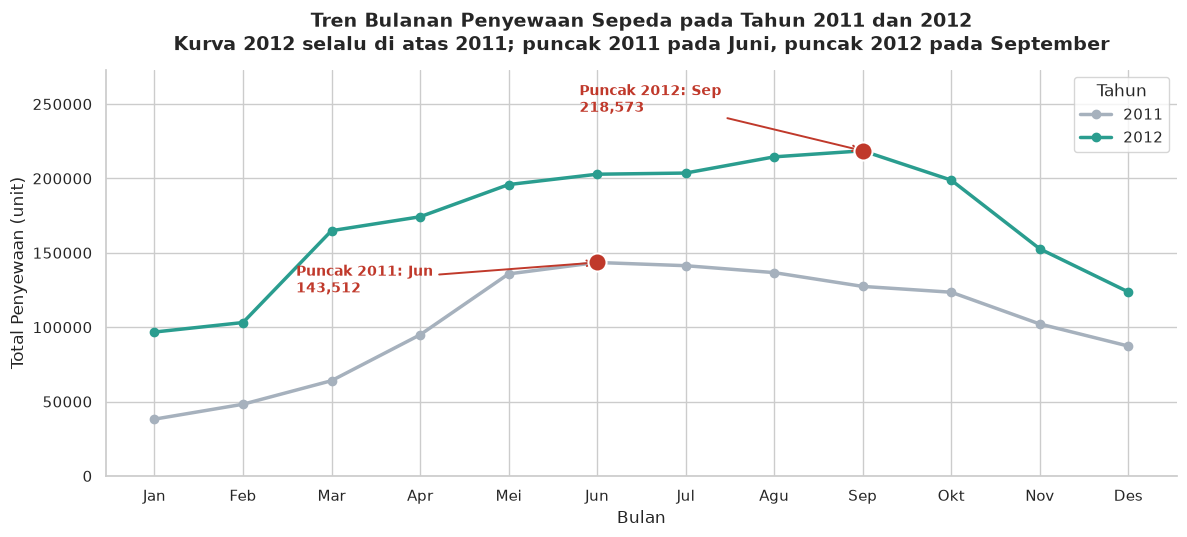

In [21]:
WARNA_2011, WARNA_2012 = '#A6B1BD', '#2A9D8F'
WARNA_PUNCAK = '#C0392B'

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(urutan_bulan))
ax.plot(x, tren_bulanan[2011].values, marker='o', lw=2.5, color=WARNA_2011, label='2011')
ax.plot(x, tren_bulanan[2012].values, marker='o', lw=2.5, color=WARNA_2012, label='2012')

for tahun_puncak, seri in [(2011, tren_bulanan[2011]), (2012, tren_bulanan[2012])]:
    posisi = int(np.argmax(seri.values))
    ax.scatter(posisi, seri.max(), s=170, color=WARNA_PUNCAK, zorder=5,
               edgecolor='white', linewidth=1.5)
    ax.annotate(f'Puncak {tahun_puncak}: {urutan_bulan[posisi]}\n{int(seri.max()):,}',
                xy=(posisi, seri.max()),
                xytext=((posisi - 3.2, seri.max() * 1.12) if tahun_puncak == 2012
                        else (posisi - 3.4, seri.max() * 0.86)),
                fontsize=10, fontweight='bold', color=WARNA_PUNCAK,
                arrowprops=dict(arrowstyle='->', color=WARNA_PUNCAK, lw=1.4))

ax.set_xticks(x)
ax.set_xticklabels(urutan_bulan)
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Penyewaan (unit)')
ax.set_title('Tren Bulanan Penyewaan Sepeda pada Tahun 2011 dan 2012\n'
             'Kurva 2012 selalu di atas 2011; puncak 2011 pada Juni, puncak 2012 pada September',
             pad=14)
ax.legend(title='Tahun')
ax.set_ylim(0, tren_bulanan.max().max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()

#### Rata-rata Penyewaan Harian per Musim pada Tahun 2011 dan 2012

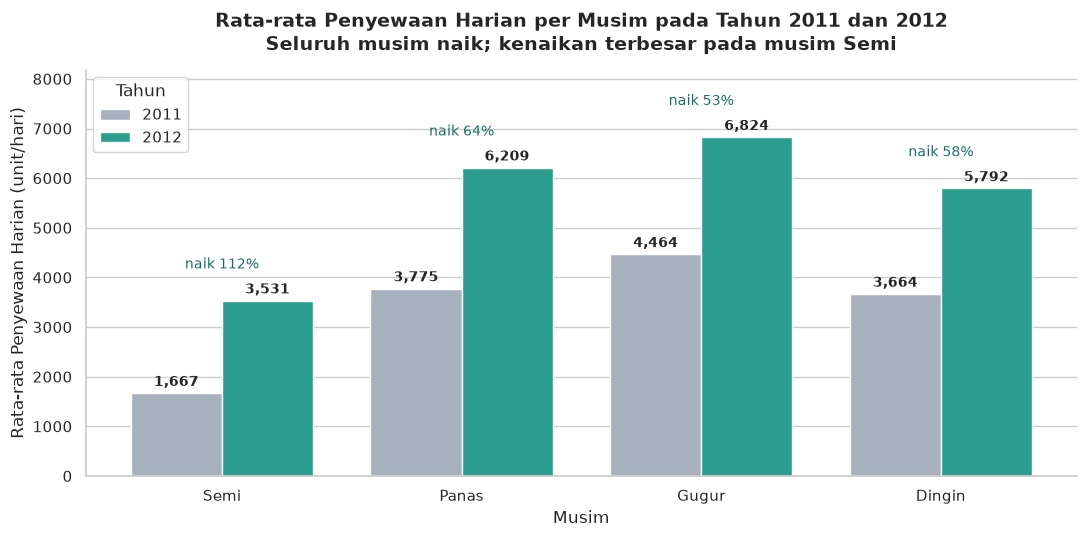

In [22]:
fig, ax = plt.subplots(figsize=(11, 5.5))
lebar = 0.38
pos = np.arange(len(urutan_musim))
b1 = ax.bar(pos - lebar / 2, musim_tahun.loc[urutan_musim, 2011], lebar,
            color=WARNA_2011, label='2011')
b2 = ax.bar(pos + lebar / 2, musim_tahun.loc[urutan_musim, 2012], lebar,
            color=WARNA_2012, label='2012')

for batang in list(b1) + list(b2):
    ax.text(batang.get_x() + batang.get_width() / 2, batang.get_height() + 80,
            f'{batang.get_height():,.0f}', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
for i, musim in enumerate(urutan_musim):
    ax.text(i, musim_tahun.loc[musim, 2012] + 650,
            f"naik {musim_tahun.loc[musim, 'kenaikan_%']:.0f}%",
            ha='center', fontsize=10, color='#1B6F66')

ax.set_xticks(pos)
ax.set_xticklabels(urutan_musim)
ax.set_xlabel('Musim')
ax.set_ylabel('Rata-rata Penyewaan Harian (unit/hari)')
ax.set_title('Rata-rata Penyewaan Harian per Musim pada Tahun 2011 dan 2012\n'
             'Seluruh musim naik; kenaikan terbesar pada musim Semi', pad=14)
ax.set_ylim(0, musim_tahun[2012].max() * 1.2)
ax.legend(title='Tahun', loc='upper left')
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

#### Rata-rata Penyewaan Harian menurut Kondisi Cuaca

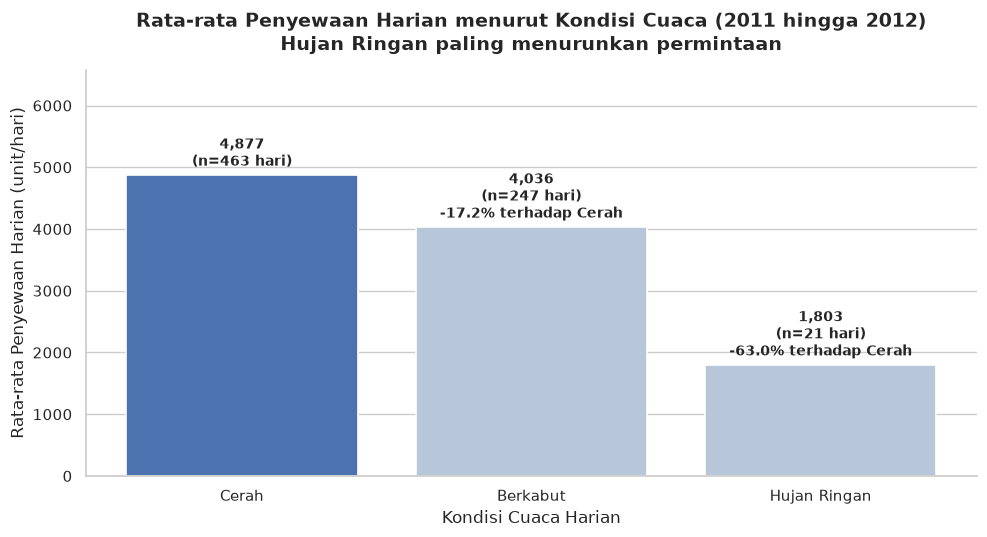

In [23]:
data_cuaca = cuaca_stats.dropna(subset=['rata_harian'])
nilai = data_cuaca['rata_harian']
warna = ['#4C72B0' if k == 'Cerah' else '#B8C6D9' for k in data_cuaca.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
batang = ax.bar(data_cuaca.index, nilai.values, color=warna, edgecolor='white', linewidth=1.2)
for b, (kondisi, baris) in zip(batang, data_cuaca.iterrows()):
    keterangan = f"{baris['rata_harian']:,.0f}\n(n={int(baris['hari'])} hari)"
    if kondisi != 'Cerah':
        keterangan += f"\n{baris['selisih_terhadap_cerah_%']:.1f}% terhadap Cerah"
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + nilai.max() * 0.015,
            keterangan, ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Kondisi Cuaca Harian')
ax.set_ylabel('Rata-rata Penyewaan Harian (unit/hari)')
ax.set_title('Rata-rata Penyewaan Harian menurut Kondisi Cuaca (2011 hingga 2012)\n'
             'Hujan Ringan paling menurunkan permintaan', pad=14)
ax.set_ylim(0, nilai.max() * 1.35)
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Kurva 2012 berada di atas 2011 pada seluruh bulan. Puncak 2011 jatuh pada Juni (143.512) dan puncak 2012 pada September (218.573), sedangkan bulan terendah adalah Januari pada kedua tahun.
- Rata-rata harian naik pada seluruh musim, dengan kenaikan terbesar pada musim Semi (sekitar 112%) dan terkecil pada musim Gugur (sekitar 53%).
- Musim Gugur tetap memiliki rata-rata harian tertinggi pada kedua tahun, sehingga musim ini menjadi prioritas perencanaan armada.
- Hujan Ringan adalah kondisi yang paling menurunkan rata-rata harian (turun 63,02% terhadap Cerah), sedangkan Berkabut turun 17,24%. Karena Hujan Ringan hanya berjumlah 21 hari, hasilnya perlu ditafsirkan dengan hati-hati.
- Implikasi: kapasitas armada dan staf dapat disesuaikan mengikuti pola musiman, dan strategi promosi dapat difokuskan pada hari berkabut atau hujan ringan untuk menstabilkan pendapatan.

### Pertanyaan 2: Jam Puncak Penyewaan pada Hari Kerja dan Hari Libur serta Komposisi Pengguna Registered dan Casual

Visualisasi pada bagian ini menjawab Pertanyaan 2: pada jam berapa permintaan mencapai puncak pada hari kerja dibandingkan dengan hari libur, serta bagaimana kontribusi pengguna `registered` terhadap pengguna `casual` pada jam-jam tersebut.

#### Pola Penyewaan per Jam pada Hari Kerja dan Hari Libur

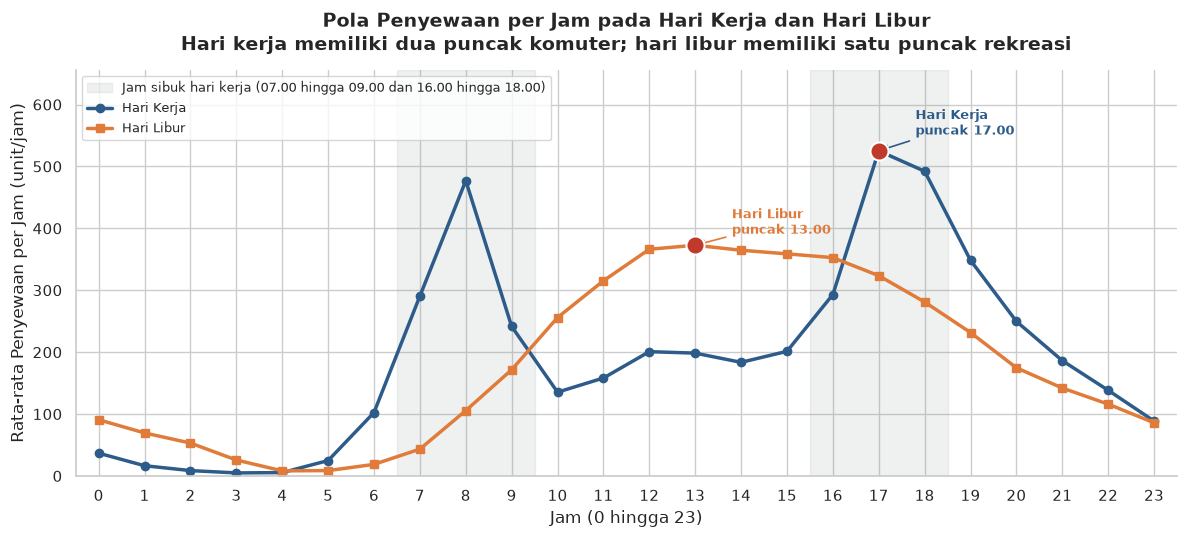

In [24]:
WARNA_KERJA, WARNA_LIBUR = '#2E5C8A', '#E07B39'

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axvspan(6.5, 9.5, alpha=0.12, color='#7F8C8D',
           label='Jam sibuk hari kerja (07.00 hingga 09.00 dan 16.00 hingga 18.00)')
ax.axvspan(15.5, 18.5, alpha=0.12, color='#7F8C8D')
ax.plot(pola_jam.index, pola_jam['Hari Kerja'], marker='o', lw=2.5,
        color=WARNA_KERJA, label='Hari Kerja')
ax.plot(pola_jam.index, pola_jam['Hari Libur'], marker='s', lw=2.5,
        color=WARNA_LIBUR, label='Hari Libur')

for jenis, warna_teks in [('Hari Kerja', WARNA_KERJA), ('Hari Libur', WARNA_LIBUR)]:
    j = pola_jam[jenis].idxmax()
    ax.scatter(j, pola_jam.loc[j, jenis], s=170, color=WARNA_PUNCAK, zorder=5,
               edgecolor='white', linewidth=1.5)
    ax.annotate(f'{jenis}\npuncak {j:02d}.00',
                xy=(j, pola_jam.loc[j, jenis]),
                xytext=(j + 0.8, pola_jam.loc[j, jenis] * 1.05),
                fontsize=9, fontweight='bold', color=warna_teks,
                arrowprops=dict(arrowstyle='->', color=warna_teks, lw=1.2))

ax.set_xticks(range(0, 24))
ax.set_xlim(-0.5, 23.5)
ax.set_xlabel('Jam (0 hingga 23)')
ax.set_ylabel('Rata-rata Penyewaan per Jam (unit/jam)')
ax.set_title('Pola Penyewaan per Jam pada Hari Kerja dan Hari Libur\n'
             'Hari kerja memiliki dua puncak komuter; hari libur memiliki satu puncak rekreasi',
             pad=14)
ax.legend(loc='upper left', fontsize=9)
ax.set_ylim(0, pola_jam.max().max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()

#### Komposisi Pengguna Registered dan Casual per Jam

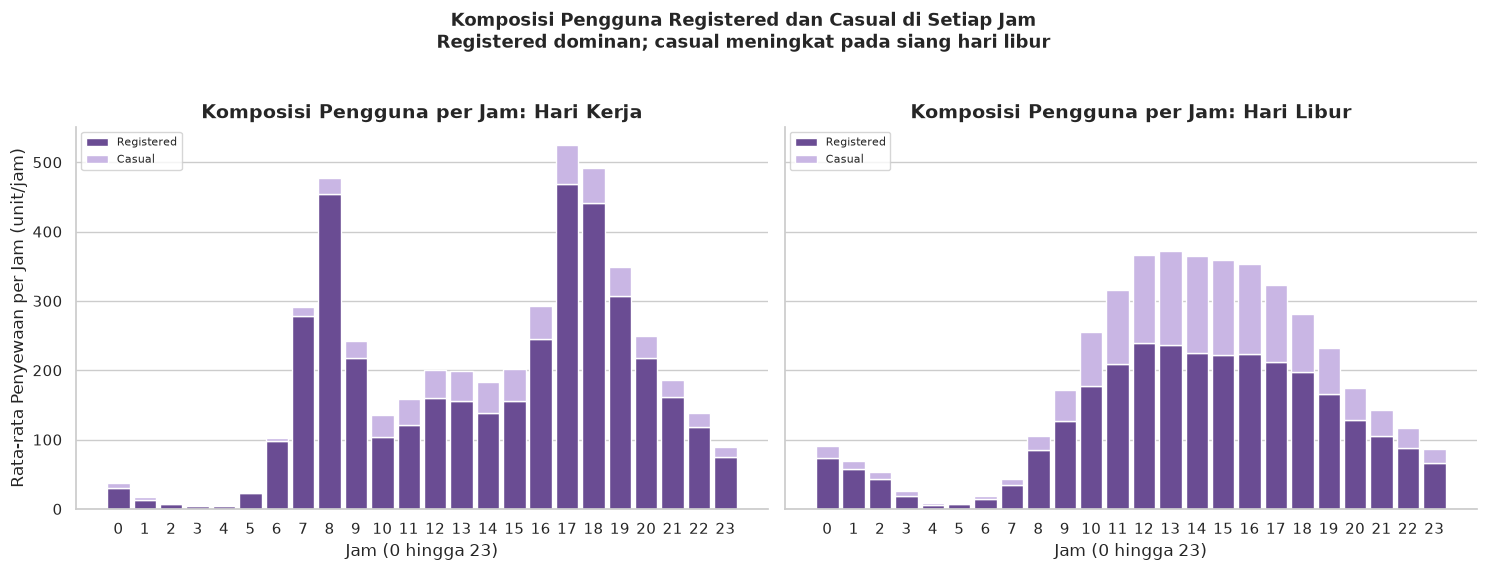

In [25]:
WARNA_REGISTERED, WARNA_CASUAL = '#6A4C93', '#C9B6E4'

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, jenis in zip(axes, ['Hari Kerja', 'Hari Libur']):
    data = komposisi.loc[jenis]
    ax.bar(data.index, data['registered'], color=WARNA_REGISTERED,
           label='Registered', width=0.85)
    ax.bar(data.index, data['casual'], bottom=data['registered'],
           color=WARNA_CASUAL, label='Casual', width=0.85)
    ax.set_xticks(range(0, 24))
    ax.set_xlabel('Jam (0 hingga 23)')
    ax.set_title(f'Komposisi Pengguna per Jam: {jenis}', fontweight='bold')
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(axis='x', visible=False)
    sns.despine(ax=ax)
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (unit/jam)')
fig.suptitle('Komposisi Pengguna Registered dan Casual di Setiap Jam\n'
             'Registered dominan; casual meningkat pada siang hari libur',
             fontweight='bold', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- Hari kerja memiliki dua puncak tajam, yaitu pukul 08.00 dan pukul 17.00 hingga 18.00 yang bertepatan dengan jam berangkat dan pulang kerja. Hari libur memiliki satu puncak yang lebih lebar pada pukul 12.00 hingga 14.00.
- Pengguna `registered` dominan pada hampir semua jam, terutama pada jam sibuk hari kerja. Porsi `casual` paling terlihat pada siang hari libur.
- Implikasi: strategi operasional perlu dibedakan antara hari kerja dan hari libur. Menyamakan keduanya berisiko menyebabkan kekurangan atau kelebihan sepeda pada jam tertentu.

## Analisis Lanjutan (Opsional)

**Tujuan:**
- Binning manual terhadap `cnt` harian menjadi tiga kelas (Rendah, Sedang, Tinggi) berbasis tertil. Kelas ini memberi bahasa operasional yang sederhana untuk keputusan armada harian.
- Segmentasi waktu per jam (Pagi, Siang, Sore, Malam) untuk melihat jendela waktu dengan permintaan tertinggi. Karena panjang segmen berbeda (Pagi 6 jam, Siang 4 jam, Sore 4 jam, Malam 10 jam), perbandingan dilakukan dengan rata-rata penyewaan per jam, bukan dengan porsi total.

In [26]:
q1, q2 = day_clean['cnt'].quantile([1 / 3, 2 / 3])
print(f'Batas kelas: Rendah < {q1:,.0f} <= Sedang < {q2:,.0f} <= Tinggi')

day_clean['demand_level'] = pd.cut(day_clean['cnt'], bins=[-np.inf, q1, q2, np.inf],
                                   labels=['Rendah', 'Sedang', 'Tinggi'])
print('\nDistribusi tingkat permintaan:')
print(day_clean['demand_level'].value_counts().sort_index())

ct_musim = pd.crosstab(day_clean['season'], day_clean['demand_level'])
ct_cuaca = pd.crosstab(day_clean['weathersit'], day_clean['demand_level'])
print('\nMusim dan tingkat permintaan:')
display(ct_musim)
print('\nKondisi cuaca dan tingkat permintaan:')
display(ct_cuaca)

Batas kelas: Rendah < 3,741 <= Sedang < 5,312 <= Tinggi

Distribusi tingkat permintaan:
demand_level
Rendah    244
Sedang    244
Tinggi    243
Name: count, dtype: int64

Musim dan tingkat permintaan:


demand_level,Rendah,Sedang,Tinggi
season,,,
Semi,140,33,8
Panas,37,71,76
Gugur,13,79,96
Dingin,54,61,63



Kondisi cuaca dan tingkat permintaan:


demand_level,Rendah,Sedang,Tinggi
weathersit,,,
Cerah,121,160,182
Berkabut,104,82,61
Hujan Ringan,19,2,0


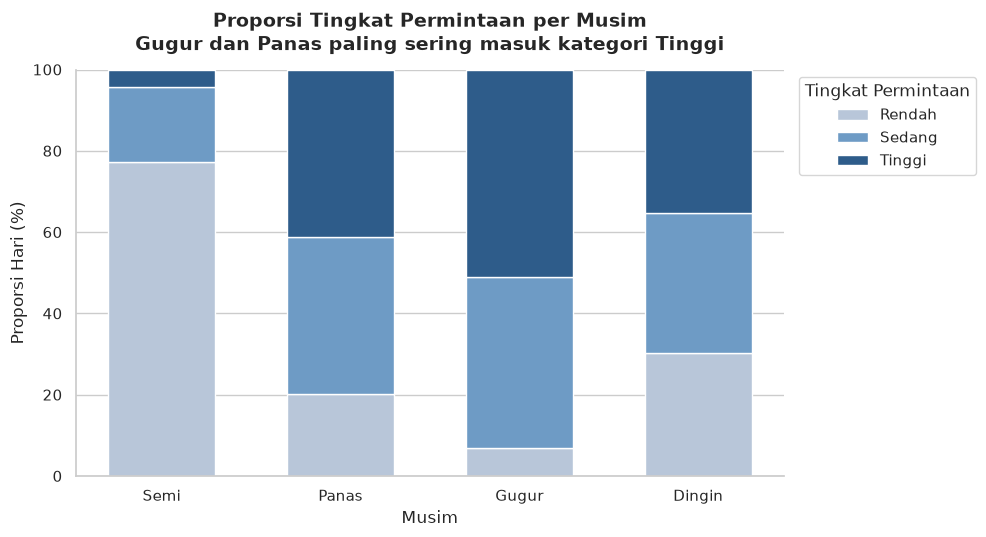

In [27]:
proporsi = ct_musim.div(ct_musim.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
warna_demand = {'Rendah': '#B8C6D9', 'Sedang': '#6E9BC5', 'Tinggi': '#2E5C8A'}
dasar = np.zeros(len(proporsi))
for tingkat in ['Rendah', 'Sedang', 'Tinggi']:
    ax.bar(proporsi.index.astype(str), proporsi[tingkat], bottom=dasar,
           color=warna_demand[tingkat], label=tingkat, edgecolor='white', width=0.6)
    dasar += proporsi[tingkat].values

ax.set_xlabel('Musim')
ax.set_ylabel('Proporsi Hari (%)')
ax.set_title('Proporsi Tingkat Permintaan per Musim\n'
             'Gugur dan Panas paling sering masuk kategori Tinggi', pad=14)
ax.set_ylim(0, 100)
ax.legend(title='Tingkat Permintaan', bbox_to_anchor=(1.01, 1))
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

In [28]:
def segmen(jam):
    if 5 <= jam < 11:
        return 'Pagi (05-10)'
    if 11 <= jam < 15:
        return 'Siang (11-14)'
    if 15 <= jam < 19:
        return 'Sore (15-18)'
    return 'Malam (19-04)'


urutan_seg = ['Pagi (05-10)', 'Siang (11-14)', 'Sore (15-18)', 'Malam (19-04)']
hour_clean['time_segment'] = pd.Categorical(hour_clean['hr'].apply(segmen),
                                            urutan_seg, ordered=True)

seg_stats = hour_clean.groupby(['day_type', 'time_segment'], observed=True).agg(
    total=('cnt', 'sum'), rata_per_jam=('cnt', 'mean'),
    casual=('casual', 'sum'), registered=('registered', 'sum')).round(1)
display(seg_stats)

seg_total = hour_clean.groupby('time_segment', observed=True).agg(
    jumlah_jam=('hr', 'nunique'), total=('cnt', 'sum'), rata_per_jam=('cnt', 'mean'))
seg_total['porsi_total_%'] = (seg_total['total'] / seg_total['total'].sum() * 100).round(2)
seg_total['rata_per_jam'] = seg_total['rata_per_jam'].round(1)
print('\nPerbandingan segmen waktu (seluruh hari):')
display(seg_total)

total  rata_per_jam  casual  registered
day_type   time_segment                                           
Hari Kerja Pagi (05-10)   630846         212.0   47400      583446
           Siang (11-14)  368527         185.3   83246      285281
           Sore (15-18)   753780         378.0  100714      653066
           Malam (19-04)  539257         109.9   71925      467332
Hari Libur Pagi (05-10)   139414         101.4   36674      102740
           Siang (11-14)  327778         354.7  117560      210218
           Sore (15-18)   303749         329.1  106442      197307
           Malam (19-04)  229328         100.1   56056      173272


Perbandingan segmen waktu (seluruh hari):


,jumlah_jam,total,rata_per_jam,porsi_total_%
time_segment,,,,
Pagi (05-10),6,770260,177.1,23.39
Siang (11-14),4,696305,239.0,21.15
Sore (15-18),4,1057529,362.5,32.12
Malam (19-04),10,768585,106.8,23.34


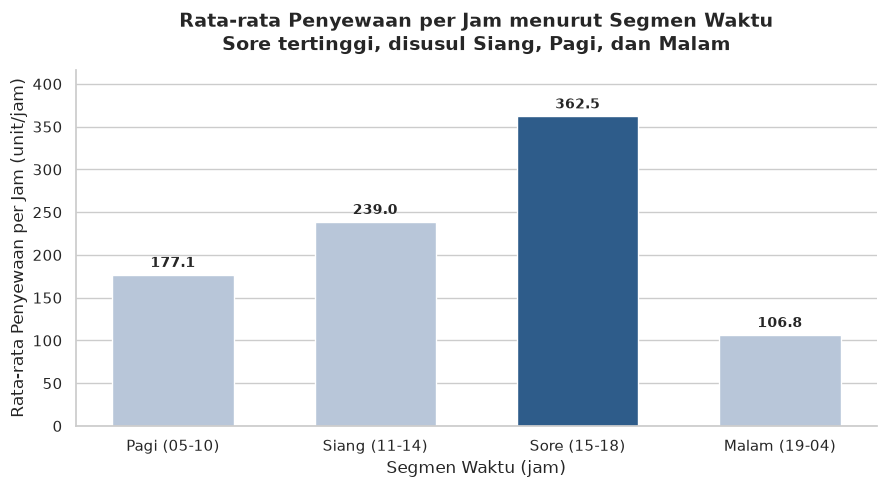

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
nilai_seg = seg_total['rata_per_jam']
warna_seg = ['#2E5C8A' if v == nilai_seg.max() else '#B8C6D9' for v in nilai_seg.values]
batang = ax.bar(nilai_seg.index.astype(str), nilai_seg.values, color=warna_seg,
                edgecolor='white', width=0.6)
for b, v in zip(batang, nilai_seg.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 5, f'{v:,.1f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xlabel('Segmen Waktu (jam)')
ax.set_ylabel('Rata-rata Penyewaan per Jam (unit/jam)')
ax.set_title('Rata-rata Penyewaan per Jam menurut Segmen Waktu\n'
             'Sore tertinggi, disusul Siang, Pagi, dan Malam', pad=14)
ax.set_ylim(0, nilai_seg.max() * 1.15)
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Binning membagi 731 hari menjadi tiga kelas dengan ukuran yang hampir seimbang (244, 244, dan 243 hari). Musim Gugur dan Panas mendominasi kelas Tinggi, sedangkan musim Semi paling banyak berada pada kelas Rendah.
- Hari Cerah paling sering berada pada kelas Tinggi (182 dari 463 hari), sedangkan Hujan Ringan hampir seluruhnya berada pada kelas Rendah (19 dari 21 hari) dan Berkabut bergeser ke kelas Rendah dan Sedang.
- Berdasarkan porsi total, Sore (32,12%) menempati urutan pertama, tetapi Pagi (23,39%) hampir sama dengan Malam (23,34%). Porsi total menyesatkan karena Malam mencakup 10 jam, sedangkan Pagi 6 jam dan Siang serta Sore masing-masing 4 jam.
- Berdasarkan rata-rata per jam, urutannya adalah Sore (362,5), Siang (239,0), Pagi (177,1), dan Malam (106,8). Siang berada di atas Pagi, dan Malam adalah segmen dengan permintaan terendah per jam.
- Pada hari kerja, Sore (378,0 per jam) lebih tinggi daripada Pagi (212,0) dan Siang (185,3). Pada hari libur, Siang (354,7) dan Sore (329,1) jauh lebih tinggi daripada Pagi (101,4).
- Hasil ini melengkapi Pertanyaan 2: selain jam puncak, terdapat blok waktu prioritas untuk armada, yaitu Sore pada hari kerja serta Siang dan Sore pada hari libur.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Total penyewaan tumbuh 64,88% dari 2011 ke 2012 (1.243.103 menjadi 2.049.576 unit, atau sekitar 1,65 kali). Per musim, rata-rata harian naik pada seluruh musim: Semi sekitar 112% (1.667 menjadi 3.531), Panas sekitar 64% (3.775 menjadi 6.209), Gugur sekitar 53% (4.464 menjadi 6.824), dan Dingin sekitar 58% (3.664 menjadi 5.792). Puncak bulanan 2011 terjadi pada Juni (143.512) dan puncak 2012 pada September (218.573), sedangkan bulan terendah pada kedua tahun adalah Januari, disusul Februari. Pada gabungan dua tahun, musim Gugur memberi kontribusi tertinggi (32,23%) dan Semi terendah (14,32%). Kondisi cuaca yang paling menurunkan rata-rata penyewaan harian adalah Hujan Ringan (turun 63,02% terhadap Cerah, dengan sampel 21 hari), sedangkan Berkabut turun 17,24%. Hujan Lebat tidak tercatat pada data harian. Korelasi terhadap `cnt`: suhu +0,63 (kuat), kecepatan angin -0,23 (sedang), dan kelembapan -0,10 (lemah).
- **Conclusion pertanyaan 2:** Hari kerja memiliki dua puncak, yaitu pukul 08.00 dan pukul 17.00 hingga 18.00 (tertinggi pukul 17.00), yang menunjukkan pola komuter. Hari libur memiliki satu puncak pada pukul 12.00 hingga 14.00 (tertinggi pukul 13.00), yang menunjukkan pola rekreasi. Pengguna `registered` berkontribusi 81,17% dari total dan dominan terutama pada jam sibuk hari kerja, sedangkan porsi `casual` meningkat pada siang hari libur. Berdasarkan rata-rata penyewaan per jam, Sore (362,5) adalah segmen waktu tertinggi, disusul Siang (239,0), Pagi (177,1), dan Malam (106,8).

**Rekomendasi Action Item:**
- **Redistribusi armada pada hari kerja.** Lakukan redistribusi sepeda pada pukul 06.00 hingga 07.30 dan pukul 16.00 hingga 17.30. Alihkan sebagian armada pada pukul 10.00 hingga 15.00 untuk perawatan karena permintaan pada jam tersebut jauh lebih rendah. Indikator keberhasilan: berkurangnya kejadian stasiun kosong pada pukul 08.00 dan 17.00.
- **Kampanye pengguna casual pada siang hari libur.** Tawarkan promo pada pukul 12.00 hingga 14.00 di titik rekreasi (taman dan tempat wisata), misalnya diskon 60 hingga 120 menit pertama. Indikator keberhasilan: kenaikan jumlah penyewaan `casual` per hari libur.
- **Antisipasi musim dan cuaca.** Tambah kapasitas armada dan petugas pada Mei hingga Oktober, saat permintaan bulanan berada pada level tertinggi. Jadwalkan perawatan besar pada Januari hingga Februari, saat permintaan terendah. Siapkan promo untuk hari berkabut atau hujan ringan guna menahan penurunan permintaan. Indikator keberhasilan: berkurangnya selisih pendapatan harian antarkondisi cuaca.
- **Pemantauan tingkat permintaan harian.** Gunakan hasil binning (Rendah, Sedang, Tinggi) sebagai acuan operasional harian. Apabila permintaan esok hari diperkirakan Tinggi, aktifkan armada tambahan sehari sebelumnya.